![](./imagenes/Diseño%20sin%20título.png)

<sub>Imagen generada con Ai</sub>

----
----

# Análisis estadístico de los resultados históricos de la Lotería de Medellín (2007–2026)

## Trabajo de Campo

Autor: Cristian David Cañas Ospina
[GitHub](https://github.com/cd7-gis)

Materia: Estadística general

----

# ¿Es compatible la cantidad de números repetidos en el premio mayor de la Lotería de Medellín entre 2007 y 2026 con la que se esperaría si cada sorteo fuera uniforme e independiente?

Base de datos: Resultados premio mayor de la loteria de Medellín

[Portal Nacional de Datos abiertos](https://www.datos.gov.co/Comercio-Industria-y-Turismo/RESULTADOS-PREMIO-MAYOR-LOTERIA-DE-MEDELLIN/|4w3i-wxax/about_data)


----
----


---
---
# Planteamiento del problema

----

Los resultados históricos de los juegos de azar permiten observar cómo se distribuyen los números ganadores a lo largo del tiempo. En el caso de la Lotería de Medellín, los registros históricos contienen información sobre los números y las series asociados al premio mayor.

Al revisar estos registros surge una pregunta: ¿qué tan frecuente es que un mismo número vuelva a resultar ganador en diferentes sorteos? Además, ¿las repeticiones observadas corresponden a un comportamiento compatible con un modelo probabilístico en el que todos los números tienen la misma posibilidad de aparecer?

El análisis busca describir el comportamiento histórico de los números ganadores y contrastar las frecuencias observadas con las frecuencias esperadas.

---
---


---
---
# Objetivo

---
Evaluar si la cantidad de números repetidos en el historico del premio mayor de la loteria de Medellín 2007 - 2026, es compatible con la frecuencia esperada bajo un modelo probabilístico de distribución uniforme e independencia entre sorteos.

----
---


---
---
# Objetivos específicos
---
1. Identificar la frecuencia de aparición de los números ganadores del premio mayor de la Lotería de Medellín durante el período 2007 - 2026, determinando cuáles presentaron repeticiones.

2. Caracterizar la distribución de frecuencias de los números ganadores mediante herramientas de estadística descriptiva.

3. Calcular las frecuencias esperadas de aparición y repetición de los números mediante modelos probabilísticos.

4. Comparar las frecuencias observadas con las esperadas para evaluar su compatibilidad con el modelo probabilístico planteado.

---
---

----

---

Este ejercicio permite aplicar conceptos de estadística descriptiva y probabilidad a una base de datos real, utilizando herramientas de programación para organizar, procesar, visualizar e interpretar información.

A través del lenguaje de programación Python y diferentes bibliotecas para el análisis de datos, se busca identificar la frecuencia de aparición de los números ganadores, reconocer cuáles se han repetido y estudiar su comportamiento frente a un modelo probabilístico.

De esta manera, se integran conocimientos de estadística con herramientas computacionales como Python, Pandas, NumPy, Matplotlib, Seaborn y SciPy.

---
---

---
---
# Metodológia
---
Se desarrolla un análisis cuantitativo, descriptivo y probabilístico, basado en registros históricos disponibles de los resultados del premio mayor de la Lotería de Medellín.

- Población:
Resultados de los números ganadores del premio mayor de la loteria de Medellín.
- Variables:
    - Variables de los datos:
    Fecha de juego, Número del sorteo, Número ganador, Serie ganadora.
    - Variable de estudio:
    Frecuencia de aparición de los números ganadores.
- Muestra:
1024 registros.

---
---

---
---

# Importante
---

Los resultados obtenidos corresponden al comportamiento histórico de los datos analizados y **no permiten** predecir los resultados de futuros sorteos **ni establecer** que un número tenga mayores probabilidades de ganar.

---
---

---
---
1. Limpieza y exploración de los datos
---
---


In [213]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy.stats import poisson



ruta = ("C:\Programacion\Analisis_loteria_medellin\data\RESULTADOS_PREMIO_MAYOR_LOTERIA_DE_MEDELLIN_20261025.csv")

df = pd.read_csv(ruta)
df.shape




(1024, 4)

In [214]:
df.columns


Index(['FECHA DE JUEGO', 'SORTEO', 'NÚMERO', 'SERIE'], dtype='object')

In [215]:
df.head()

,FECHA DE JUEGO,SORTEO,NÚMERO,SERIE
0,2007 Jan 05 12:00:00 AM,3834,3652,149
1,2007 Jan 12 12:00:00 AM,3835,9407,80
2,2007 Jan 19 12:00:00 AM,3836,9864,97
3,2007 Jan 26 12:00:00 AM,3837,5589,54
4,2007 Feb 02 12:00:00 AM,3838,1721,102


In [216]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1024 entries, 0 to 1023
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   FECHA DE JUEGO  1024 non-null   object
 1   SORTEO          1024 non-null   int64 
 2   NÚMERO          1024 non-null   int64 
 3   SERIE           1024 non-null   int64 
dtypes: int64(3), object(1)
memory usage: 32.1+ KB


In [217]:

df.isnull().sum()


FECHA DE JUEGO    0
SORTEO            0
NÚMERO            0
SERIE             0
dtype: int64

In [218]:

df.dtypes


FECHA DE JUEGO    object
SORTEO             int64
NÚMERO             int64
SERIE              int64
dtype: object

In [219]:

df["NÚMERO"].astype(str).str.len().value_counts().sort_index()


NÚMERO
2      7
3     89
4    928
Name: count, dtype: int64

In [220]:
df['NÚMERO'] = df['NÚMERO'].astype(str).str.zfill(4)
df['SERIE'] = df['SERIE'].astype(str).str.zfill(3)

df[['SERIE', 'NÚMERO']].head(15)

,SERIE,NÚMERO
0,149,3652
1,080,9407
2,097,9864
3,054,5589
4,102,1721
5,111,5318
6,189,3407
7,164,5723
8,175,1047
9,193,1563


In [221]:

df["FECHA DE JUEGO"].head(15)



0     2007 Jan 05 12:00:00 AM
1     2007 Jan 12 12:00:00 AM
2     2007 Jan 19 12:00:00 AM
3     2007 Jan 26 12:00:00 AM
4     2007 Feb 02 12:00:00 AM
5     2007 Feb 09 12:00:00 AM
6     2007 Feb 16 12:00:00 AM
7     2007 Feb 23 12:00:00 AM
8     2007 Mar 02 12:00:00 AM
9     2007 Mar 09 12:00:00 AM
10    2007 Mar 16 12:00:00 AM
11    2007 Mar 23 12:00:00 AM
12    2007 Mar 30 12:00:00 AM
13    2007 Apr 04 12:00:00 AM
14    2007 Apr 13 12:00:00 AM
Name: FECHA DE JUEGO, dtype: object

In [222]:
df['FECHA DE JUEGO'] = pd.to_datetime(
    df['FECHA DE JUEGO'],
    dayfirst=True,
    errors="coerce"
    )


df["FECHA DE JUEGO"].dtype


C:\Users\Usuario\AppData\Local\Temp\ipykernel_20140\3631443182.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['FECHA DE JUEGO'] = pd.to_datetime(


dtype('<M8[ns]')

In [223]:

print("Fechas inválidas:", df["FECHA DE JUEGO"].isna().sum())
print("Primera fecha:", df["FECHA DE JUEGO"].min())
print("Última fecha:", df["FECHA DE JUEGO"].max())


Fechas inválidas: 0
Primera fecha: 2007-01-05 00:00:00
Última fecha: 2026-10-09 00:00:00


---
---
2. Estadística descriptiva
---
---

In [224]:

df[["FECHA DE JUEGO", "NÚMERO", "SERIE"]].describe(include="all")


,FECHA DE JUEGO,NÚMERO,SERIE
count,1024,1024,1024
unique,NaN,962,364
top,NaN,0169,053
freq,NaN,3,10
mean,2016-11-16 11:57:11.250000128,NaN,NaN
min,2007-01-05 00:00:00,NaN,NaN
25%,2011-11-30 06:00:00,NaN,NaN
50%,2016-10-31 12:00:00,NaN,NaN
75%,2021-11-20 18:00:00,NaN,NaN
max,2026-10-09 00:00:00,NaN,NaN


In [225]:
frecuencia_numeros = df["NÚMERO"].value_counts()
frecuencia_serie = df['SERIE'].value_counts()


print(frecuencia_numeros.head(10), frecuencia_serie.head(10))

NÚMERO
0169    3
0539    3
2570    3
3257    2
0575    2
5589    2
1721    2
5318    2
2350    2
0099    2
Name: count, dtype: int64 SERIE
053    10
073     8
120     7
164     7
152     7
218     7
166     7
169     7
180     6
231     6
Name: count, dtype: int64


---
---
# Análisis
---

Encontramos un conjunto de datos que abarca casi 20 años de regitros de los números ganadores del premio mayor de la loteria de Medellín, desde 05 de enero de 2007 hasta 9 de octubre del 2026.

Se identificaron cuatro variables: fecha de juego, sorteo, número ganador y serie.

Hay un total de **1024 registros históricos** analizados, **962** números y **364** series son diferentes.

Los números 0539, 0169 y 2570 presentaron la mayor frecuencia de aparición, con tres registros cada uno. Por otra parte, la serie 053 fue la más frecuente, con diez apariciones.

---
---


In [226]:
mediana = frecuencia_numeros.median()
media = frecuencia_numeros.mean()
moda = frecuencia_numeros.mode().to_list()

st = frecuencia_numeros.std()
varianza = frecuencia_numeros.var()

coeficiente_variacion = st / media * 100

resumen = pd.DataFrame({
    "Medida": ["n", "Media", "Mediana",
              "Moda", "Mínimo","Máximo",
              "Rango", "Varianza", "Desviación estándar",
              "Coef. de variación (%)"],
    "Valor": [len(df['NÚMERO']), media, mediana, moda[0],
             frecuencia_numeros.min(), frecuencia_numeros.max(),
            frecuencia_numeros.max() - frecuencia_numeros.min(),
             varianza, st, coeficiente_variacion,
              ]
})

print(resumen)

                   Medida        Valor
0                       n  1024.000000
1                   Media     1.064449
2                 Mediana     1.000000
3                    Moda     1.000000
4                  Mínimo     1.000000
5                  Máximo     3.000000
6                   Rango     2.000000
7                Varianza     0.066602
8     Desviación estándar     0.258073
9  Coef. de variación (%)    24.244739


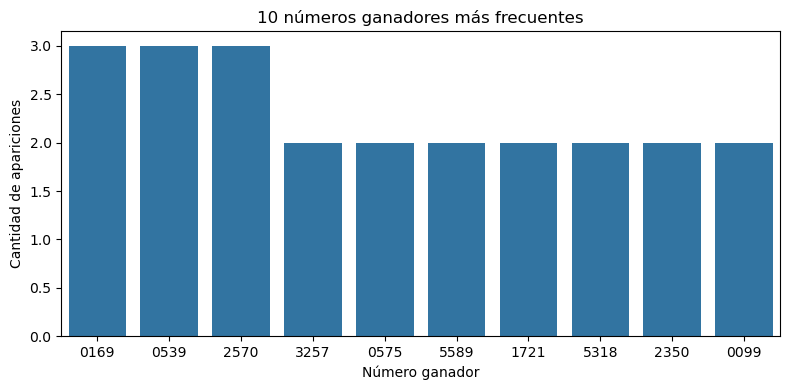

In [227]:
top_10 =frecuencia_numeros.head(10).reset_index()
top_10.columns = ["Número", "Frecuencia"]

plt.figure(figsize=(8, 4))
sns.barplot(
    data=top_10,
    x="Número",
    y="Frecuencia",
)

plt.title("10 números ganadores más frecuentes")
plt.xlabel("Número ganador")
plt.ylabel("Cantidad de apariciones")
plt.tight_layout()
plt.show()

---
---
# Análisis
---

Se observaron 962 números y 364 series distintos.

El número más repetido fue 0539, con 3 apariciones, y la serie más repetida fue 053, con 10 apariciones. La mayoría de los números apareció una sola vez; algunos se repitieron dos veces y tres números 0539, 0169 y 2570 aparecieron tres veces.

Estas frecuencias describen el comportamiento histórico del sorteo, pero no permiten concluir que un número tenga mayor probabilidad de ganar en futuros sorteos.

---
---


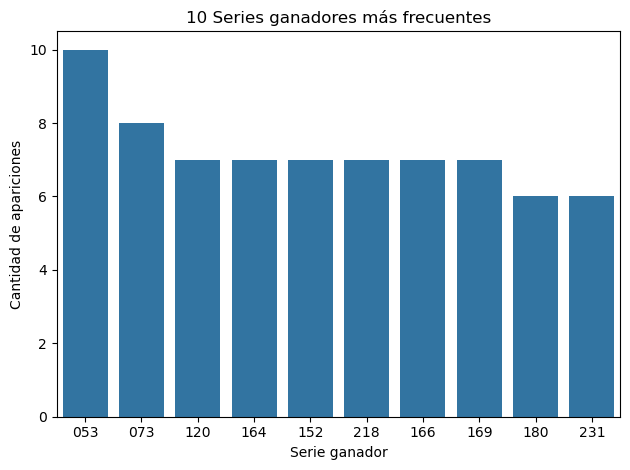

In [228]:
top_10 =frecuencia_serie.head(10).reset_index()
top_10.columns = ["Serie", "Frecuencia"]

sns.barplot(
    data=top_10,
    x="Serie",
    y="Frecuencia"
)

plt.title("10 Series ganadores más frecuentes")
plt.xlabel("Serie ganador")
plt.ylabel("Cantidad de apariciones")
plt.tight_layout()
plt.show()

In [229]:

distribucion_frecuencias = frecuencia_numeros.value_counts().sort_index()

distribucion_frecuencias

count
1    903
2     56
3      3
Name: count, dtype: int64

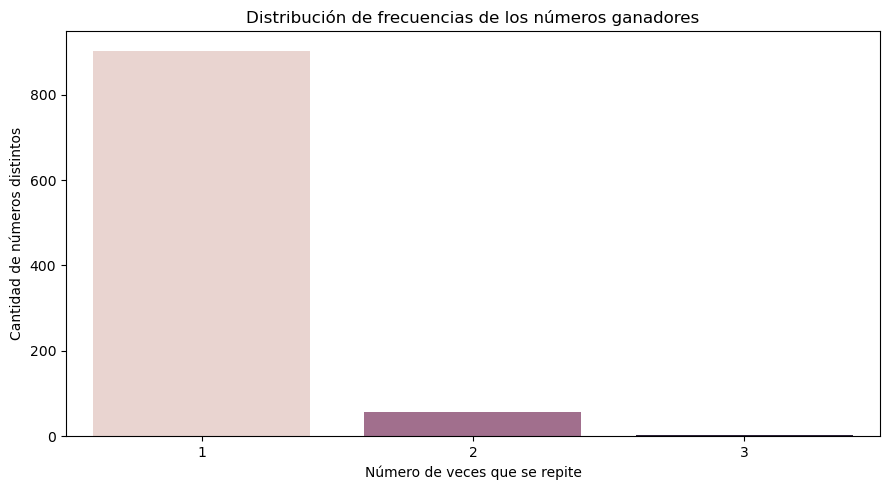

In [230]:

tabla_distribucion = distribucion_frecuencias.rename_axis(
    "Veces que apareció el número"
).reset_index(name="Cantidad de números")

plt.figure(figsize=(9, 5))

sns.barplot(
    data=tabla_distribucion,
    x="Veces que apareció el número",
    y="Cantidad de números",
    hue="Veces que apareció el número",
    legend=False
)

plt.title("Distribución de frecuencias de los números ganadores")
plt.xlabel("Número de veces que se repite")
plt.ylabel("Cantidad de números distintos")
plt.tight_layout()
plt.show()


---
---
# Análisis
---
Se calcularon las frecuencias absolutas de los números y las series registrados en la base de datos.

Esta gráfica muestra la distribución de la frecuencia de veces que se repitio cada número con respecto a la cantidad de números distintos.

Dentro de los 1024 registros, 962 son números distintos.
* 903 salieron una vez
* 56 salieron dos veces
* 3 salieron 3 veces

Estos resultados describen una frecuencia historica de los números ganadores durante 5 enero del 2007 y 9 octubre del 2026, pero **no permite** concluir que los que han aparecido más veces tengan una mayor probabilidad de ganar.

---
---


In [231]:

registro_year = df['FECHA DE JUEGO'].dt.year.value_counts().sort_index()
print(registro_year)

FECHA DE JUEGO
2007    52
2008    52
2009    52
2010    53
2011    52
2012    52
2013    52
2014    52
2015    52
2016    51
2017    52
2018    52
2019    52
2020    45
2021    53
2022    52
2023    52
2024    52
2025    53
2026    41
Name: count, dtype: int64


---
---
# Análisis
---
Entre 2007 y 2025, la mayoría de los años presenta entre 51 y 53 registros. Se identifican algunas diferencias, como los 45 registros de 2020.

Esta distribución permite contextualizar la cantidad de sorteos analizados y reconocer que los años no tienen necesariamente la misma cantidad de registros.

---
---

---
---
3. Modelo probabilidad
---
n = 1024

p =  1 / 10000 = 0.0001

$\lambda$ = np = 1024(0.0001) = 0.1024

k = número de apariciones = 1, 2, 3

e = euler


$$
Fórmula Poisson
$$
$$
P(X = k) = e^{-λ} . λ^{k} / k!
$$

---
$$
Fórmula
$$
$$
P(X = k) = e^{- 0.1024}. 0.1024^{(k)} / (k) !
$$

$$
k ∈  {(1, 2, 3)}
$$

---

La distribución de Poisson se utiliza como aproximación al modelo binomial cuando se tiene una cantidad relativamente grande de ensayos, una probabilidad de éxito pequeña y un valor de \(np\) conocido.

---
---

In [232]:
n_sorteos = len(df)
n_opcion = 10000
prob_exitos = 1 / n_opcion

prob_exitos_porcen = prob_exitos * 100

aparicion_esperada = n_sorteos * prob_exitos

esperados_dife = n_opcion * (
    1 - (1 - 1 / n_opcion) **
    n_sorteos
)

observados_distintos = df["NÚMERO"].nunique()

lambd = n_sorteos * prob_exitos

for k in range(4):
    probab_k = (
        math.exp(-lambd) * lambd ** k
    / math.factorial(k)
    )
    print(k, probab_k)
    cantidad_esperada = probab_k * n_opcion
    print(
        "Apariciones:", k,
        "| Probabilidad:", round(probab_k, 5),
        "| Cantidad esperada:", round(cantidad_esperada, 2)
    )

desviacion_poisson = math.sqrt(lambd)


0 0.9026684120809421
Apariciones: 0 | Probabilidad: 0.90267 | Cantidad esperada: 9026.68
1 0.09243324539708847
Apariciones: 1 | Probabilidad: 0.09243 | Cantidad esperada: 924.33
2 0.00473258216433093
Apariciones: 2 | Probabilidad: 0.00473 | Cantidad esperada: 47.33
3 0.00016153880454249577
Apariciones: 3 | Probabilidad: 0.00016 | Cantidad esperada: 1.62


In [233]:
resultados = []

for k in range(4):
    if k == 0:
        observados = n_opcion - len(frecuencia_numeros)
    else:
        observados = frecuencia_numeros.value_counts().get(k, 0)

    probabilidad_k = poisson.pmf(k, mu=lambd)

    esperados = probabilidad_k * n_opcion

    resultados.append({
        "Apariciones": k,
        "Observados": observados,
        "Probabilidad Poisson": probabilidad_k,
        "Esperados probabilidad": esperados
    })

tabla_poisson = pd.DataFrame(resultados)

tabla_poisson

,Apariciones,Observados,Probabilidad Poisson,Esperados probabilidad
0,0,9038,0.902668,9026.684121
1,1,903,0.092433,924.332454
2,2,56,0.004733,47.325822
3,3,3,0.000162,1.615388


---
---
# Análisis
---

La distribución de Poisson permitió estimar la cantidad esperada de combinaciones de cuatro cifras que podrían aparecer cero, una, dos o tres veces, considerando 1.024 sorteos y 10.000 resultados posibles bajo los supuestos de uniformidad e independencia.

Al comparar los resultados observados con los esperados, se identificaron diferencias en las distintas categorías de frecuencia. Por ejemplo, se observaron 56 combinaciones con dos apariciones, frente a aproximadamente 47,33 esperadas, y 3 combinaciones con tres apariciones, frente a aproximadamente 1,62 esperadas.

Estas diferencias describen el comportamiento de los registros frente al modelo teórico, pero no permiten demostrar por sí solas la existencia de sesgos ni confirmar que el mecanismo de sorteo sea completamente aleatorio e independiente.

---
---


In [234]:
distribucion_frecuencias


count
1    903
2     56
3      3
Name: count, dtype: int64

In [235]:
tabla_distribucion = distribucion_frecuencias.rename_axis(
    "Veces que aparecio el número"
).reset_index(name='Cantidad de números')


In [236]:
tabla_comparativa = pd.DataFrame({
    "Apariciones": range(4)
})

tabla_comparativa = tabla_comparativa.merge(
    tabla_poisson[["Apariciones", "Observados"]],
    on="Apariciones",
    how="left"
)

tabla_comparativa = tabla_comparativa.merge(
    tabla_poisson[["Apariciones", "Esperados probabilidad"]],
    on="Apariciones",
    how="left"
)

tabla_comparativa["Diferencia"] = (
    tabla_comparativa["Observados"]
    - tabla_comparativa["Esperados probabilidad"]
)

tabla_comparativa

,Apariciones,Observados,Esperados probabilidad,Diferencia
0,0,9038,9026.684121,11.315879
1,1,903,924.332454,-21.332454
2,2,56,47.325822,8.674178
3,3,3,1.615388,1.384612


<Figure size 900x500 with 0 Axes>

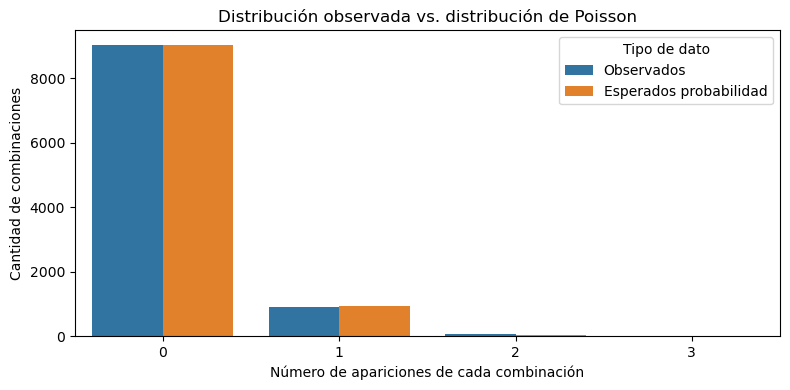

In [237]:

plt.figure(figsize=(9, 5))

tabla_grafica = tabla_comparativa.melt(
    id_vars="Apariciones",
    value_vars=["Observados", "Esperados probabilidad"],
    var_name="Tipo de dato",
    value_name="Cantidad de números"
)

plt.figure(figsize=(8, 4))

sns.barplot(
    data=tabla_grafica,
    x="Apariciones",
    y="Cantidad de números",
    hue="Tipo de dato"
)

plt.title("Distribución observada vs. distribución de Poisson")
plt.xlabel("Número de apariciones de cada combinación")
plt.ylabel("Cantidad de combinaciones")
plt.legend(title="Tipo de dato")
plt.tight_layout()
plt.show()


In [238]:
tabla_grafica

,Apariciones,Tipo de dato,Cantidad de números
0,0,Observados,9038.000000
1,1,Observados,903.000000
2,2,Observados,56.000000
3,3,Observados,3.000000
4,0,Esperados probabilidad,9026.684121
5,1,Esperados probabilidad,924.332454
6,2,Esperados probabilidad,47.325822
7,3,Esperados probabilidad,1.615388


---
---
# Conclusiones
---

Se analizaron 1.024 registros históricos del premio mayor de la Lotería de Medellín, comprendidos entre el 5 de enero de 2007 y el 9 de octubre de 2026.

Se identificaron 962 números distintos de cuatro cifras y 364 series diferentes. De los números analizados, 903 aparecieron una vez, 56 aparecieron dos veces y 3 aparecieron tres veces.

Los números 0539, 0169 y 2570 presentaron la mayor frecuencia de aparición, con tres registros cada uno. Estos resultados corresponden a frecuencias históricas y no representan una mayor probabilidad de ganar en futuros sorteos.

Mediante el modelo teórico de Poisson, con un parámetro de 0,1024, se estimaron las frecuencias esperadas de aparición de las combinaciones de cuatro cifras bajo los supuestos de uniformidad e independencia.

El análisis permite caracterizar el comportamiento histórico de los resultados, pero no permite predecir futuros números ganadores ni demostrar por sí solo que el mecanismo de sorteo sea completamente aleatorio o esté libre de sesgos.

---
---


---
---
# Propuesta de solución
---
Promover el uso de herramientas estadísticas para analizar los resultados históricos de los juegos de azar, fomentando la comprensión de las frecuencias y evitando interpretaciones erróneas que lleven a considerar que los números que han aparecido anteriormente tienen mayores probabilidades de aparecer en futuros sorteos.

---
---

----
----

# LINK Y REFERENCIAS
---

https://docs.python.org/es/3/tutorial/index.html

https://pandas.pydata.org/docs/user_guide/index.html

https://numpy.org/doc/stable/user/absolute_beginners.html

https://matplotlib.org/stable/users/getting_started/

https://matplotlib.org/stable/plot_types/index.html

https://www.practicalpythonfordatascience.com/ap_seaborn_palette

https://seaborn.pydata.org/index.html

https://docs.python.org/3/library/math.html

https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html

https://www.datos.gov.co/Comercio-Industria-y-Turismo/RESULTADOS-PREMIO-MAYOR-LOTERIA-DE-MEDELLIN/4w3i-wxax/about_data

----
----
